<div align="center">

# 02 · Patrones de consumo y tipos de día

*Hourly Energy Consumption (PJM Interconnection)*

</div>

---

**Entrada:** `data/processed/consumo_horario.parquet` (datos limpios, en MW reales).
**Funciones:** `src/features.py` (`agregar_variables_temporales`, `normalizar_por_region`), `src/profiles.py`
**Parámetros:** `src/config.py` (`K_MIN`, `K_MAX`, `TAMANO_MIN_GRUPO`, `SILUETA_RAZONABLE`, `SILUETA_DEBIL`, `MUESTRA_AGRUPAMIENTO`, `SEMILLA`)
**Salida:** `data/processed/tipos_de_dia*.parquet` (días con su grupo, curvas, resumen, mezcla por región y silueta por k), que el notebook 07 exporta para Power BI.

**Día operativo.** `Datetime` marca el final de la hora, así que las variables de calendario (`fecha`, `anio`, `mes`, `hora`, `dia_semana`, `es_festivo`) se calculan desde `Datetime − 1 h`: el registro de las 00:00 pertenece a la hora 23 del día anterior y `hora` va de 0 (00:00–01:00) a 23. Todos los promedios y picos diarios usan la columna `fecha`.

**Qué datos usa cada sección:** las comparaciones entre regiones usan las regiones vigentes en su periodo común; la estacionalidad, la tendencia y los picos usan todo el historial de cada región.

El notebook tiene dos partes: **A. Análisis descriptivo** (qué patrones hay a simple vista) y **B. Agrupamiento** (qué tipos de día descubre el algoritmo).

| Parte | Sección | Qué responde | Historia de usuario |
|---|---|---|---|
| A | 1 | Patrones por hora, día de la semana y estación | HU-01 |
| A | 2 | Estacionalidad y tendencia de largo plazo | HU-02 |
| A | 3 | Comparación entre regiones | HU-03 |
| A | 4 | Periodos de máxima demanda | HU-04 |
| A | 5 | Efecto de los festivos | Variable `es_festivo` |
| A | 6 | Empalmes entre regiones | Calidad y comparabilidad |
| B | 7 | Perfiles diarios y diagnóstico de desfase horario | Insumo del agrupamiento |
| B | 8 | Elección de k | P1 |
| B | 9 | Agrupamiento, forma y ubicación en el calendario | P1 |
| B | 10 | Diferencias entre regiones | P2 |
| B | 11 | Días que no encajan en su grupo | P3 (insumo) |
| B | 12 | Guardado | Salida para el notebook 07 |
| — | 13 | Conclusiones y limitaciones | Resultados esperados |

Un **tipo de día** es un grupo de días con la misma *forma* de curva de demanda a lo largo de las 24 horas. No se define por el calendario: el algoritmo descubre los grupos y después se mira en qué fechas cae cada uno.

**Diseño del experimento (Parte B)**

| Elemento | Decisión |
|---|---|
| Unidad | Un día operativo (`Datetime − 1 h`) de una región, con sus 24 horas |
| Representación | 24 valores, cada uno dividido entre el promedio del día: se compara la forma y no el nivel (el nivel se guarda aparte en `MW_medio_dia`) |
| Métodos | k-medias y agrupamiento jerárquico (Ward) |
| Número de grupos | k entre `K_MIN` y `K_MAX`, elegido con la silueta media |
| Criterios de cierre | Silueta media reportada (≥ 0.50 estructura razonable; 0.26 a 0.50 débil) y grupos con al menos el 5 % de los días |
| Alcance | Las 12 regiones juntas, para que los tipos de día sean los mismos y se pueda construir la matriz región por tipo de día |

## 0. Configuración y carga

In [39]:
%load_ext autoreload
%autoreload 2

import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from sklearn.metrics import adjusted_rand_score
from statsmodels.tsa.seasonal import STL

from src.features import agregar_variables_temporales, normalizar_por_region
from src.profiles import (
    construir_perfiles, elegir_k, recomendar_k, agrupar, calendario_dias,
    describir_grupos, curvas_grupo, mezcla_por_region, tabla_dias,
)
from src.config import (
    PROCESSED_DIR, HORAS_POR_DIA, K_MIN, K_MAX, TAMANO_MIN_GRUPO,
    SILUETA_RAZONABLE, SILUETA_DEBIL,
)

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 11, "legend.frameon": False})
pd.set_option("display.max_columns", None)   # evita que pandas esconda columnas con ....

DIAS = ['Lun', 'Mar', 'Mié', 'Jue', 'Vie', 'Sáb', 'Dom']
MESES = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
ESTACIONES = ['Invierno', 'Primavera', 'Verano', 'Otoño']

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### Parámetros de este notebook

- **`REGION_STL` y `REGION_CALENDARIO`:** región que se descompone con STL (sección 2.3) y región que se dibuja en el calendario de tipos de día (sección 9.4).
- **`ALINEAR_HORA_CENTRAL`:** `COMED` llega una hora más tarde que el resto. Es lo esperable si todas las series están en hora del este y `COMED` está en hora central. Con `False` se conserva la hora de la fuente; con `True` se resta 1 h a las regiones de `REGIONES_HORA_CENTRAL` **solo para el agrupamiento (Parte B)**, de modo que su curva quede alineada con las demás. La sección 7.1 mide el desfase de cada región para decidir.
- **`K_ELEGIDO` y `METODO_ELEGIDO`:** con `None` se usa la combinación recomendada por la silueta (sección 8). Para fijar otra, escribe el valor y justifícalo en la sección 8.

In [40]:
REGION_STL = 'PJME'
REGION_CALENDARIO = 'PJME'

ALINEAR_HORA_CENTRAL = False
REGIONES_HORA_CENTRAL = ['COMED', 'NI']   # NI se comprueba en la sección 7.1

K_ELEGIDO = None         # por ejemplo, 4; None = el recomendado por la silueta
METODO_ELEGIDO = None    # 'kmeans' o 'ward'; None = el recomendado

In [41]:
df = pd.read_parquet(PROCESSED_DIR / "consumo_horario.parquet")
df = normalizar_por_region(agregar_variables_temporales(df))

print(f"{len(df):,} filas · {df['region'].nunique()} regiones")
df.head()

1,090,343 filas · 12 regiones


,Datetime,MW,region,fecha,anio,mes,hora,dia_semana,es_fin_de_semana,estacion,es_festivo,MW_rel
0,2004-10-01 01:00:00,12379.0,AEP,2004-10-01,2004,10,0,4,False,Otoño,False,0.798689
1,2004-10-01 02:00:00,11935.0,AEP,2004-10-01,2004,10,1,4,False,Otoño,False,0.770042
2,2004-10-01 03:00:00,11692.0,AEP,2004-10-01,2004,10,2,4,False,Otoño,False,0.754364
3,2004-10-01 04:00:00,11597.0,AEP,2004-10-01,2004,10,3,4,False,Otoño,False,0.748235
4,2004-10-01 05:00:00,11681.0,AEP,2004-10-01,2004,10,4,4,False,Otoño,False,0.753654


---
# Parte A · Análisis descriptivo

### Regiones vigentes y periodo común

Las regiones vigentes son las que llegan hasta el final del dataset. Sus datos dentro del periodo común (`df_comun`) son los que se comparan entre sí.

In [42]:
cobertura = df.groupby('region')['Datetime'].agg(inicio='min', fin='max')

corte = cobertura['fin'].max() - pd.Timedelta(days=7)
vigentes = cobertura[cobertura['fin'] >= corte]
inicio_comun, fin_comun = vigentes['inicio'].max(), vigentes['fin'].min()

df_comun = df[df['region'].isin(vigentes.index) & df['Datetime'].between(inicio_comun, fin_comun)]

print(f"Regiones vigentes ({len(vigentes)}): {list(vigentes.index)}")
print(f"Periodo común: {inicio_comun:%Y-%m-%d} → {fin_comun:%Y-%m-%d}")
print("Fuera de la comparación:", [r for r in cobertura.index if r not in vigentes.index])

Regiones vigentes (10): ['AEP', 'COMED', 'DAYTON', 'DEOK', 'DOM', 'DUQ', 'EKPC', 'FE', 'PJME', 'PJMW']
Periodo común: 2013-06-01 → 2018-08-03
Fuera de la comparación: ['NI', 'PJM_Load']


### Años completos y promedio diario

Para tendencia y picos anuales solo se usan los años con (casi) todas sus horas; si no, un año parcial (como 2018, que llega hasta agosto) parecería una caída. El promedio diario se calcula por `fecha` (día operativo) y exige las 24 horas para no promediar días con datos faltantes.

In [43]:
por_anio = df.groupby(['region', 'anio'])['MW'].agg(media='mean', maximo='max', horas='count')
por_anio['completo'] = por_anio['horas'] >= 8700

print(f"{int(por_anio['completo'].sum())} de {len(por_anio)} combinaciones región-año son completas")
completos = por_anio[por_anio['completo']].reset_index()[['region', 'anio']]


def promedio_diario(d):
    """Promedio por día operativo (region, fecha), solo para días de 24 horas."""
    g = d.groupby(['region', 'fecha'])['MW']
    return g.mean()[g.count() == HORAS_POR_DIA]

114 de 132 combinaciones región-año son completas


## 1. Patrones temporales

### 1.1 Hora del día por día de la semana

Consumo relativo al promedio de cada región (regiones vigentes, periodo común). Muestra cómo interactúan las dos variables, algo que los perfiles por separado no capturan.

C:\Users\lukas\AppData\Local\Temp\ipykernel_22512\2252322753.py:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout(rect=[0, 0, 0.9, 1])


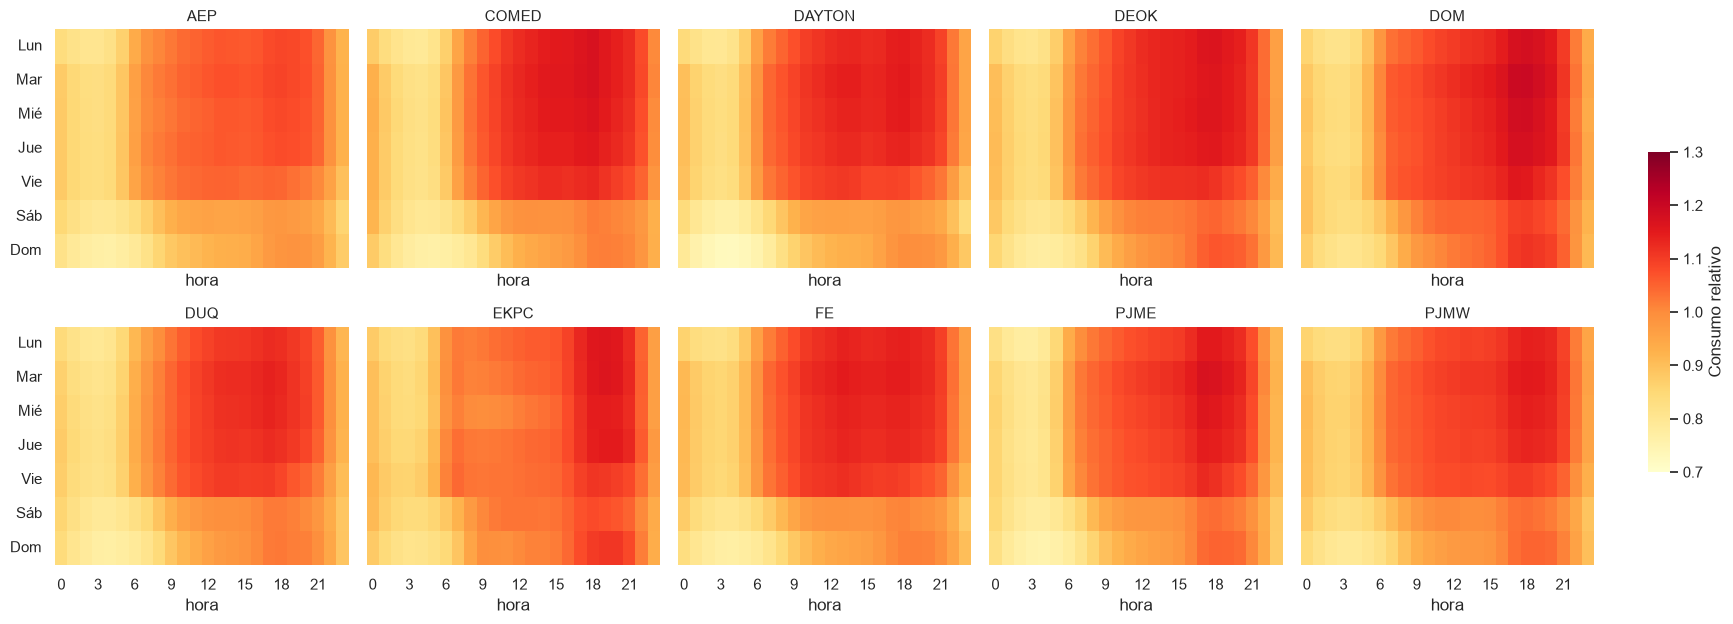

In [44]:
regs = list(vigentes.index)
ncols = 5
nrows = math.ceil(len(regs) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3.2 * nrows), sharex=True, sharey=True, squeeze=False)
cbar_ax = fig.add_axes([0.92, 0.25, 0.012, 0.5])

for i, (ax, nombre) in enumerate(zip(axes.flat, regs)):
    p = (df_comun[df_comun['region'] == nombre]
         .groupby(['dia_semana', 'hora'])['MW_rel'].mean().unstack())
    sns.heatmap(p, ax=ax, cmap='YlOrRd', vmin=0.7, vmax=1.3, yticklabels=DIAS, xticklabels=3,
                cbar=(i == 0), cbar_ax=cbar_ax if i == 0 else None,
                cbar_kws={'label': 'Consumo relativo'})
    ax.set_title(nombre)
    ax.set_xlabel('hora')
    ax.set_ylabel('')
    ax.tick_params(axis='y', rotation=0)
for ax in axes.flat[len(regs):]:
    ax.axis('off')

fig.tight_layout(rect=[0, 0, 0.9, 1])
plt.show()

### 1.2 Perfil horario por estación

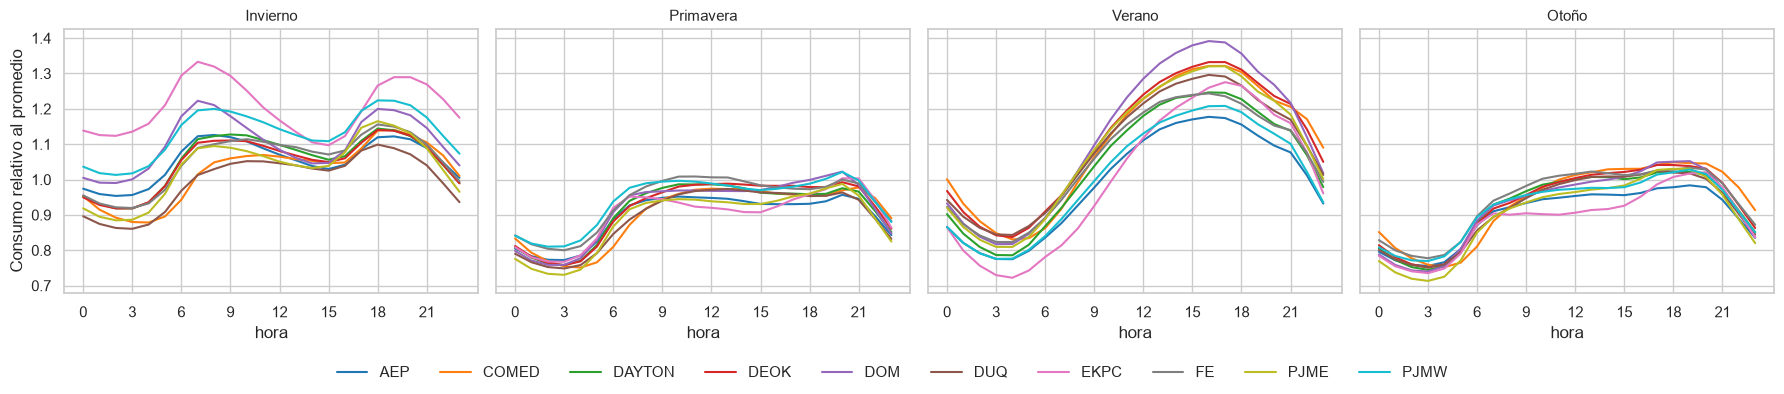

In [45]:
colores_reg = dict(zip(vigentes.index, sns.color_palette('tab10', len(vigentes))))

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
for ax, est in zip(axes, ESTACIONES):
    p = (df_comun[df_comun['estacion'] == est]
         .groupby(['region', 'hora'])['MW_rel'].mean().unstack(0))
    for region in p.columns:
        ax.plot(p.index, p[region], color=colores_reg[region], label=region)
    ax.set_title(est)
    ax.set_xlabel('hora')
    ax.set_xticks(range(0, 24, 3))
axes[0].set_ylabel('Consumo relativo al promedio')

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels))
fig.tight_layout(rect=[0, 0.08, 1, 1])
plt.show()

## 2. Estacionalidad y tendencia

### 2.1 Tendencia por región

Promedio diario (línea tenue) y media móvil de 365 días (línea gruesa), que cancela la estacionalidad anual. Usa todo el historial de cada región y solo días completos.

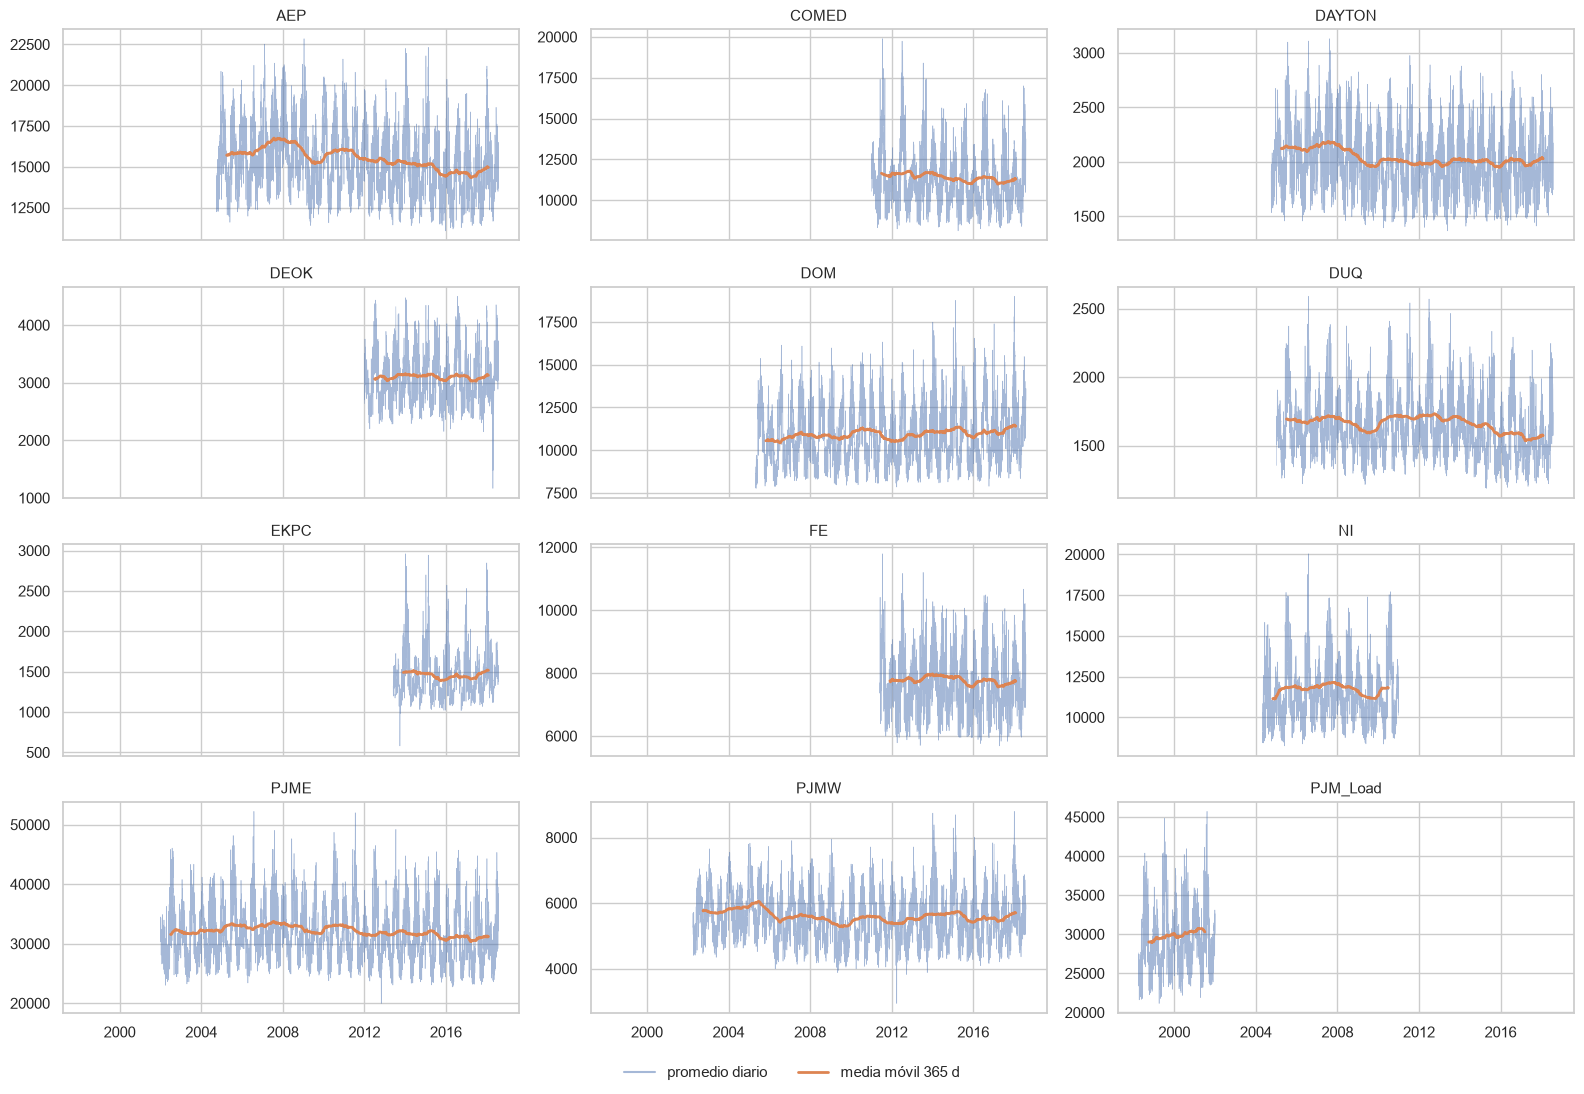

In [46]:
diario = promedio_diario(df)
nombres = list(cobertura.index)

fig, axes = plt.subplots(4, 3, figsize=(16, 11), sharex=True)
for ax, nombre in zip(axes.flat, nombres):
    s = diario[nombre]
    ax.plot(s.index, s.values, lw=0.4, alpha=0.5, color='C0')
    ax.plot(s.index, s.rolling(365, center=True).mean(), lw=2, color='C1')
    ax.set_title(nombre)
for ax in axes.flat[len(nombres):]:
    ax.axis('off')

fig.legend(handles=[plt.Line2D([], [], color='C0', alpha=0.5, label='promedio diario'),
                    plt.Line2D([], [], color='C1', lw=2, label='media móvil 365 d')],
           loc='lower center', ncol=2)
fig.tight_layout(rect=[0, 0.03, 1, 1])
plt.show()

### 2.2 Consumo medio por año completo

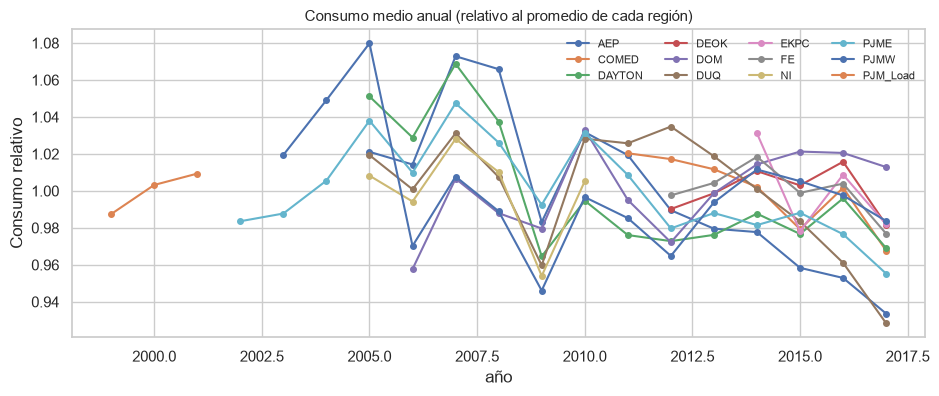

region,AEP,COMED,DAYTON,DEOK,DOM,DUQ,EKPC,FE,NI,PJME,PJMW,PJM_Load
anio,,,,,,,,,,,,
1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29639.0
2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30113.0
2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30297.0
2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31563.0,NaN,NaN
2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,31697.0,5700.0,NaN
2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,32268.0,5866.0,NaN
2005,15843.0,NaN,2142.0,NaN,NaN,1693.0,NaN,NaN,11851.0,33309.0,6038.0,NaN
2006,15736.0,NaN,2096.0,NaN,10456.0,1663.0,NaN,NaN,11687.0,32407.0,5425.0,NaN
2007,16645.0,NaN,2178.0,NaN,10990.0,1713.0,NaN,NaN,12085.0,33612.0,5635.0,NaN


In [47]:
anual = por_anio[por_anio['completo']]['media'].unstack(0).sort_index()

fig, ax = plt.subplots(figsize=(11, 4))
(anual / anual.mean()).plot(ax=ax, marker='o', ms=4)
ax.set_title('Consumo medio anual (relativo al promedio de cada región)')
ax.set_ylabel('Consumo relativo')
ax.set_xlabel('año')
ax.legend(ncol=4, fontsize=8)
plt.show()

anual.round(0)

### 2.3 Descomposición STL

Separa la serie diaria en tendencia, estacionalidad anual y residuo. La región se elige con `REGION_STL`.

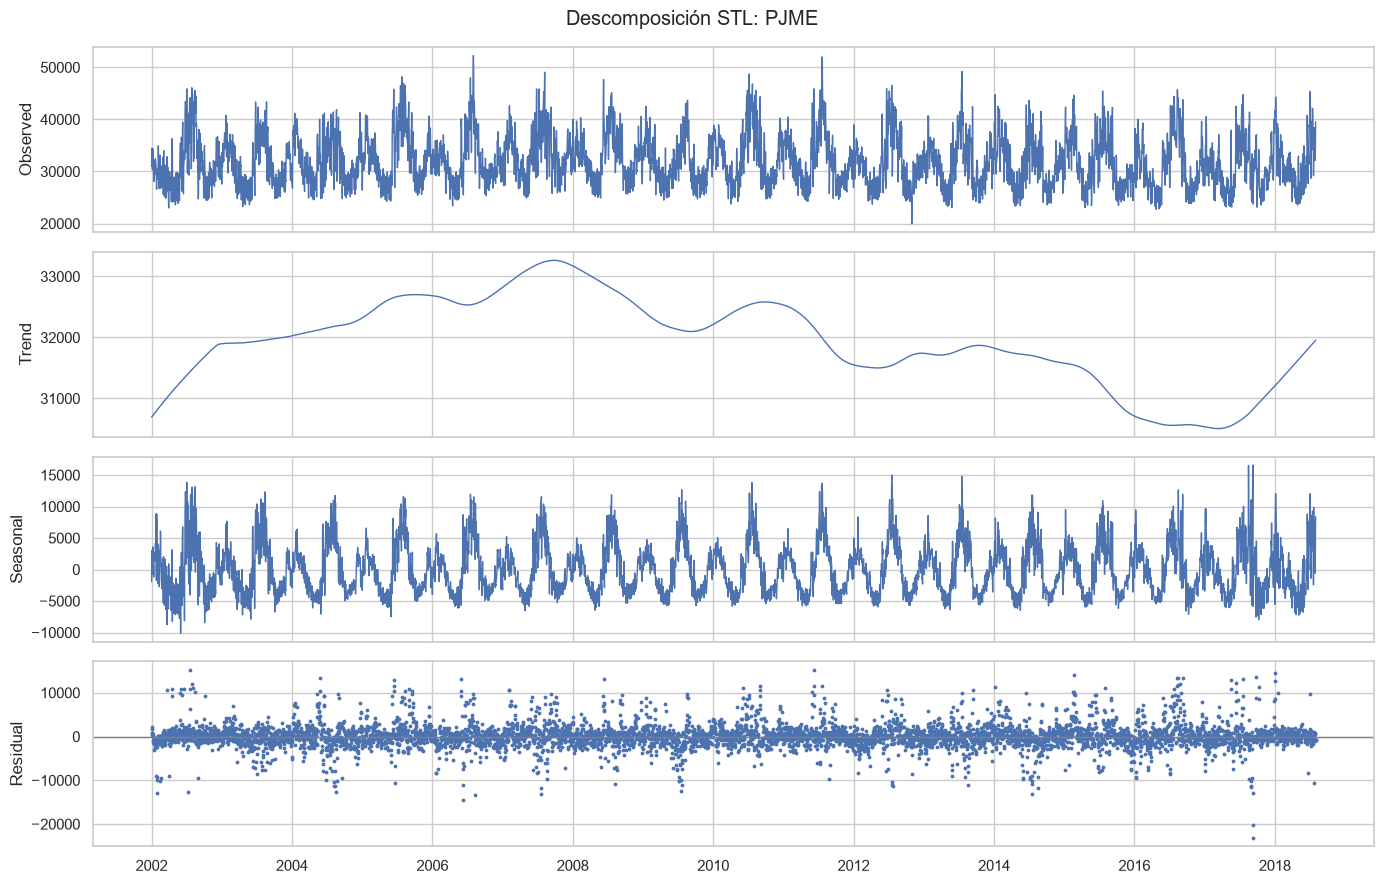

In [48]:
serie = diario[REGION_STL].asfreq('D').interpolate()
resultado = STL(serie, period=365, robust=True).fit()

componentes = [('Observed', resultado.observed), ('Trend', resultado.trend),
               ('Seasonal', resultado.seasonal), ('Residual', resultado.resid)]

fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for ax, (nombre, s) in zip(axes, componentes):
    if nombre == 'Residual':
        ax.scatter(s.index, s.values, s=3)
        ax.axhline(0, color='gray', lw=1)
    else:
        ax.plot(s.index, s.values, lw=1)
    ax.set_ylabel(nombre)
fig.suptitle(f'Descomposición STL: {REGION_STL}')
fig.tight_layout()
plt.show()

## 3. Comparación entre regiones

Regiones vigentes en su periodo común. Cada columna resume una característica del consumo:

- `CV_%`: variabilidad relativa (desviación estándar entre la media).
- `pico/media`: cuánto se dispara el máximo respecto al promedio.
- `invierno/verano`: consumo medio de invierno entre el de verano (mayor que 1: región invernal).
- `fin_de_semana_%`: diferencia del consumo de fin de semana frente a días laborables.
- `hora_pico`: hora del día con mayor consumo promedio.

In [49]:
g = df_comun.groupby('region')['MW']
perfil_horario = df_comun.groupby(['region', 'hora'])['MW'].mean().unstack(0)

media_estacion = df_comun.groupby(['region', 'estacion'])['MW'].mean().unstack()
media_finde = df_comun.groupby(['region', 'es_fin_de_semana'])['MW'].mean().unstack()

resumen_regiones = pd.DataFrame({
    'media_MW': g.mean(),
    'CV_%': g.std() / g.mean() * 100,
    'pico/media': g.max() / g.mean(),
    'invierno/verano': media_estacion['Invierno'] / media_estacion['Verano'],
    'fin_de_semana_%': (media_finde[True] / media_finde[False] - 1) * 100,
    'hora_pico': perfil_horario.idxmax(),
})
resumen_regiones.round(2)

,media_MW,CV_%,pico/media,invierno/verano,fin_de_semana_%,hora_pico
region,,,,,,
AEP,14900.18,16.94,1.66,1.06,-9.52,18
COMED,11361.78,19.73,1.96,0.93,-11.19,18
DAYTON,2008.91,18.95,1.69,1.01,-13.90,18
DEOK,3119.96,19.36,1.70,0.95,-9.23,18
DOM,11169.09,22.20,1.94,0.98,-6.09,18
DUQ,1621.70,18.69,1.82,0.92,-8.80,17
EKPC,1464.23,25.87,2.38,1.20,-3.92,19
FE,7791.76,16.93,1.69,1.00,-11.63,18
PJME,31477.51,20.48,1.88,0.95,-9.21,17


### 3.1 Correlación entre regiones

Se calcula sobre el promedio diario. Valores altos indican que las regiones suben y bajan juntas, en buena parte por compartir la estacionalidad.

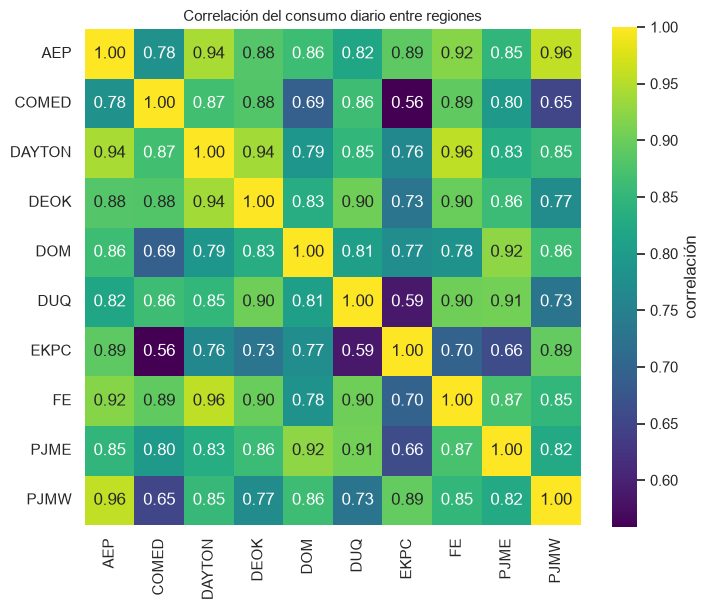

In [50]:
diario_comun = promedio_diario(df_comun).unstack(0)

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(diario_comun.corr(), annot=True, fmt='.2f', cmap='viridis', square=True,
            cbar_kws={'label': 'correlación'}, ax=ax)
ax.set_title('Correlación del consumo diario entre regiones')
ax.set_xlabel('')
ax.set_ylabel('')
plt.show()

## 4. Periodos de máxima demanda

Usa todo el historial de cada región.

### 4.1 Máximo de cada región y los 5 días de mayor pico

`fecha` es el día operativo y `hora` la hora de inicio (7 = 07:00–08:00).

In [51]:
idx = df.groupby('region')['MW'].idxmax()
maximos = df.loc[idx, ['region', 'fecha', 'hora', 'MW', 'estacion']].set_index('region')
maximos['pico/media'] = maximos['MW'] / df.groupby('region')['MW'].mean()
maximos.round({'MW': 1, 'pico/media': 2})

,fecha,hora,MW,estacion,pico/media
region,,,,,
AEP,2008-10-20,13,25695.0,Otoño,1.66
COMED,2011-07-20,17,23753.0,Verano,2.08
DAYTON,2007-08-08,14,3746.0,Verano,1.84
DEOK,2012-06-29,15,5445.0,Verano,1.75
DOM,2015-02-20,7,21651.0,Invierno,1.98
DUQ,2012-06-29,13,3054.0,Verano,1.84
EKPC,2015-02-20,7,3490.0,Invierno,2.38
FE,2011-07-21,15,14032.0,Verano,1.80
NI,2006-08-01,16,23631.0,Verano,2.02


In [52]:
max_diario = df.groupby(['region', 'fecha'])['MW'].max()

top_dias = (max_diario.groupby(level='region', group_keys=False).nlargest(5)
            .rename('MW_pico').reset_index())
top_dias['dia'] = top_dias['fecha'].dt.strftime('%Y-%m-%d')
top_dias.pivot_table(index=top_dias.groupby('region').cumcount() + 1,
                     columns='region', values='dia', aggfunc='first')

region,AEP,COMED,DAYTON,DEOK,DOM,DUQ,EKPC,FE,NI,PJME,PJMW,PJM_Load
1,2008-10-20,2011-07-20,2007-08-08,2012-06-29,2015-02-20,2012-06-29,2015-02-20,2011-07-21,2006-08-01,2006-08-02,2015-02-20,2001-08-09
2,2007-08-08,2011-07-21,2007-08-09,2012-07-17,2018-01-07,2006-08-03,2018-01-02,2011-07-22,2006-07-31,2006-08-03,2015-02-19,2001-08-08
3,2007-08-09,2012-07-06,2005-07-25,2012-07-25,2018-01-03,2006-08-02,2014-01-29,2012-07-17,2006-08-02,2011-07-22,2015-02-24,2001-08-07
4,2007-08-23,2012-07-17,2006-08-01,2012-07-06,2018-01-02,2012-07-17,2014-01-06,2011-07-20,2006-07-17,2006-08-01,2014-01-07,2001-07-25
5,2006-08-02,2012-07-05,2007-08-07,2016-07-25,2012-07-07,2011-07-21,2014-01-24,2013-07-18,2007-08-07,2011-07-21,2018-01-05,2001-08-10


### 4.2 ¿A qué hora ocurre el pico de cada día?

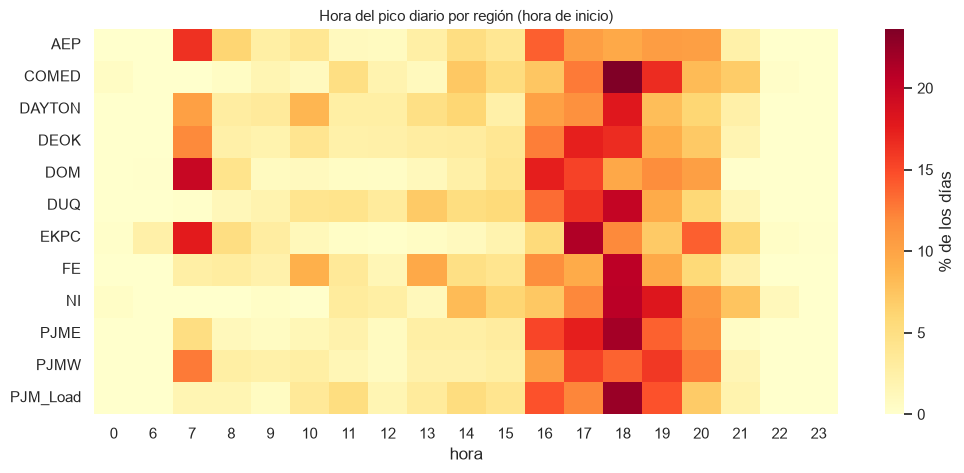

In [53]:
pico_dia = df.loc[df.groupby(['region', 'fecha'])['MW'].idxmax()]
horas_pico = pd.crosstab(pico_dia['region'], pico_dia['hora'], normalize='index') * 100

fig, ax = plt.subplots(figsize=(12, 5))
sns.heatmap(horas_pico, cmap='YlOrRd', cbar_kws={'label': '% de los días'}, ax=ax)
ax.set_title('Hora del pico diario por región (hora de inicio)')
ax.set_xlabel('hora')
ax.set_ylabel('')
plt.show()

### 4.3 Pico anual: en qué mes ocurre y cuánto vale (años completos)

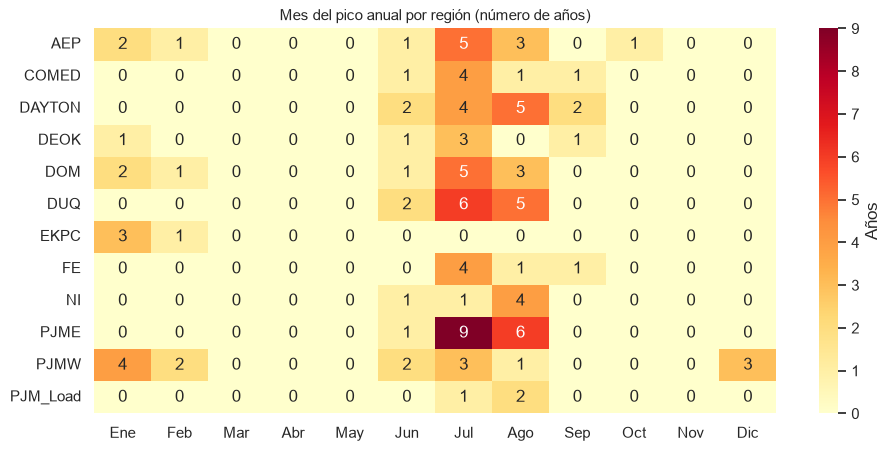

region,AEP,COMED,DAYTON,DEOK,DOM,DUQ,EKPC,FE,NI,PJME,PJMW,PJM_Load
anio,,,,,,,,,,,,
1999,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51714.0
2000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,49462.0
2001,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,54030.0
2002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,55934.0,NaN,NaN
2003,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,53737.0,8437.0,NaN
2004,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,51962.0,8598.0,NaN
2005,24015.0,NaN,3722.0,NaN,NaN,2885.0,NaN,NaN,21635.0,59031.0,8823.0,NaN
2006,24842.0,NaN,3693.0,NaN,19395.0,3053.0,NaN,NaN,23631.0,62009.0,8734.0,NaN
2007,25164.0,NaN,3746.0,NaN,19709.0,2890.0,NaN,NaN,21972.0,59437.0,8664.0,NaN


In [54]:
pico_anual = df.loc[df.groupby(['region', 'anio'])['MW'].idxmax()]
pico_anual = pico_anual.merge(completos, on=['region', 'anio'])

meses_pico = pd.crosstab(pico_anual['region'], pico_anual['mes']).reindex(columns=range(1, 13), fill_value=0)
meses_pico.columns = MESES

fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(meses_pico, annot=True, fmt='d', cmap='YlOrRd', cbar_kws={'label': 'Años'}, ax=ax)
ax.set_title('Mes del pico anual por región (número de años)')
ax.set_xlabel('')
ax.set_ylabel('')
plt.show()

pico_anual.pivot(index='anio', columns='region', values='MW').round(0)

## 5. Efecto de los festivos

Los festivos son los federales de EE. UU. (aproximación: PJM abarca varios estados con calendarios propios). Se compara el perfil horario de días laborables, fines de semana y festivos. Con el día operativo, las 24 horas de cada festivo (incluida la hora 23, que cierra a las 00:00) se cuentan en el festivo y no en el día siguiente.

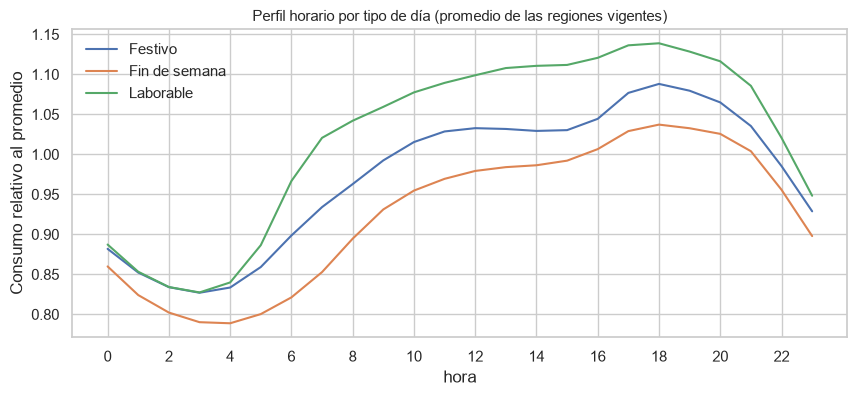

In [55]:
df_comun = df_comun.assign(
    tipo_dia=np.select(
        [df_comun['es_festivo'], df_comun['es_fin_de_semana']],
        ['Festivo', 'Fin de semana'],
        default='Laborable',
    )
)

perfil_tipo = df_comun.groupby(['tipo_dia', 'hora'])['MW_rel'].mean().unstack(0)

fig, ax = plt.subplots(figsize=(10, 4))
perfil_tipo.plot(ax=ax)
ax.set_title('Perfil horario por tipo de día (promedio de las regiones vigentes)')
ax.set_ylabel('Consumo relativo al promedio')
ax.set_xlabel('hora')
ax.set_xticks(range(0, 24, 2))
ax.legend(title='')
plt.show()

In [56]:
medias_tipo = df_comun.groupby(['region', 'tipo_dia'])['MW'].mean().unstack()
dif_festivo = pd.DataFrame({
    'festivo_vs_laborable_%': (medias_tipo['Festivo'] / medias_tipo['Laborable'] - 1) * 100,
    'finde_vs_laborable_%': (medias_tipo['Fin de semana'] / medias_tipo['Laborable'] - 1) * 100,
})
dif_festivo.round(1)

,festivo_vs_laborable_%,finde_vs_laborable_%
region,,
AEP,-5.2,-9.6
COMED,-7.8,-11.4
DAYTON,-8.8,-14.1
DEOK,-5.8,-9.4
DOM,-0.7,-6.1
DUQ,-4.7,-8.9
EKPC,1.7,-3.8
FE,-8.3,-11.9
PJME,-4.8,-9.3


## 6. Empalmes entre regiones

Si una región termina cuando empieza otra y representan la misma zona, sus niveles deberían ser parecidos en el empalme. Se comparan las medias de los últimos 30 días de la primera y los primeros 30 de la segunda. Es solo una pista: los dos tramos son de épocas distintas del año y las regiones pueden diferir en tamaño.

*(El desfase horario de `COMED` y `NI` se diagnostica en la sección 7.1, junto con la construcción de los perfiles diarios.)*

In [57]:
empalmes = [('NI', 'COMED'), ('PJM_Load', 'PJME'), ('PJM_Load', 'PJMW')]
filas = []

for a, b in empalmes:
    da = df[df['region'] == a]
    db = df[df['region'] == b]
    fin_a, inicio_b = da['Datetime'].max(), db['Datetime'].min()
    ultimos = da[da['Datetime'] > fin_a - pd.Timedelta(days=30)]['MW'].mean()
    primeros = db[db['Datetime'] < inicio_b + pd.Timedelta(days=30)]['MW'].mean()
    filas.append({
        'termina': a, 'fin': fin_a,
        'empieza': b, 'inicio': inicio_b,
        'media_ultimos_30d': ultimos,
        'media_primeros_30d': primeros,
        'cociente': primeros / ultimos,
    })

pd.DataFrame(filas).round({'media_ultimos_30d': 0, 'media_primeros_30d': 0, 'cociente': 2})

,termina,fin,empieza,inicio,media_ultimos_30d,media_primeros_30d,cociente
0,NI,2011-01-01,COMED,2011-01-01 01:00:00,12230.0,12242.0,1.00
1,PJM_Load,2002-01-01,PJME,2002-01-01 01:00:00,29679.0,31091.0,1.05
2,PJM_Load,2002-01-01,PJMW,2002-04-01 01:00:00,29679.0,5170.0,0.17


**Interpretación.** `NI` → `COMED` tiene un cociente cercano a 1 y las dos series se tocan el 2011-01-01 (`NI` termina a las 00:00 y `COMED` empieza a las 01:00), así que representan la misma zona y la evidencia permite unirlas en una serie más larga (decisión D3, por confirmar). `PJM_Load` → `PJME` es compatible con una continuación. `PJM_Load` → `PJMW` da un cociente muy bajo, por lo que `PJMW` es una subzona aparte y no un empalme.

---
# Parte B · Agrupamiento de perfiles diarios (tipos de día)

## 7. Perfiles diarios

`construir_perfiles` convierte la serie horaria en una tabla con **una fila por día y región y 24 columnas** (una por hora), y divide cada fila entre el promedio de su día. Un valor de 1.1 significa 10 % por encima del promedio de ese día. Solo se conservan los días con las 24 horas; los extremos incompletos de cada serie se descartan. Los días de cambio de horario conservan sus 24 filas porque la limpieza estimó o promedió la hora afectada.

Si `ALINEAR_HORA_CENTRAL = True`, se recalculan las variables de calendario con la hora de `COMED` y `NI` corrida −1 h (solo para esta parte; la Parte A no se toca).

In [58]:
if ALINEAR_HORA_CENTRAL:
    base = pd.read_parquet(PROCESSED_DIR / "consumo_horario.parquet")
    centrales = base['region'].isin(REGIONES_HORA_CENTRAL)
    base.loc[centrales, 'Datetime'] -= pd.Timedelta(hours=1)   # hora local central = hora del este − 1 h
    df_agr = agregar_variables_temporales(base)
    del base
else:
    df_agr = df    # misma tabla de la Parte A (hora de la fuente)

perfiles, nivel = construir_perfiles(df_agr)

print(f"{len(df_agr):,} filas · alineación a hora central: {ALINEAR_HORA_CENTRAL}")
print("Cada perfil suma 24 (promedio 1 por 24 horas):", bool(np.allclose(perfiles.sum(axis=1), HORAS_POR_DIA)))

(perfiles.reset_index()
 .groupby('region')['fecha'].agg(desde='min', hasta='max', dias='size'))

Días descartados por tener menos de 24 horas: 1
Perfiles: 45,430 días en 12 regiones
1,090,343 filas · alineación a hora central: False
Cada perfil suma 24 (promedio 1 por 24 horas): True


,desde,hasta,dias
region,,,
AEP,2004-10-01,2018-08-02,5054
COMED,2011-01-01,2018-08-02,2771
DAYTON,2004-10-01,2018-08-02,5054
DEOK,2012-01-01,2018-08-02,2406
DOM,2005-05-01,2018-08-02,4842
DUQ,2005-01-01,2018-08-02,4962
EKPC,2013-06-01,2018-08-02,1889
FE,2011-06-02,2018-08-02,2619
NI,2004-05-01,2010-12-31,2436


### 7.1 Diagnóstico: ¿está alguna región desplazada en horas?

Para cada región se compara su forma media del día con la del resto, desplazada entre -3 y +3 horas. Un desplazamiento distinto de 0 indica que su curva llega esas horas antes o después. El resto incluye a las otras regiones desplazadas, así que la medida es aproximada, pero basta para detectar `COMED` y comprobar `NI`. Si se activa `ALINEAR_HORA_CENTRAL`, las regiones alineadas deberían pasar a 0.

In [59]:
medio = perfiles.groupby('region').mean()   # forma media de cada región (24 columnas)

filas = []
for r in medio.index:
    ref = medio.drop(index=r).mean().to_numpy()
    errores = {k: np.abs(medio.loc[r].to_numpy() - np.roll(ref, k)).mean() for k in range(-3, 4)}
    filas.append({
        'region': r,
        'hora_pico': int(medio.loc[r].idxmax()),
        'desplazamiento_h': min(errores, key=errores.get),
    })

pd.DataFrame(filas).set_index('region')

,hora_pico,desplazamiento_h
region,,
AEP,18,0
COMED,18,1
DAYTON,18,0
DEOK,18,0
DOM,18,0
DUQ,17,0
EKPC,19,0
FE,18,0
NI,18,1


**Cómo decidir.** En la ejecución anterior `COMED` y `NI` salieron con +1 h y el resto con 0: es lo esperable si todas las series están en hora del este y esas dos zonas son de hora central (Chicago). Si siguen desplazadas, el algoritmo puede separar días por la hora y no por la forma, y la mezcla de tipos de día de esas regiones no sería comparable con la de las demás. En ese caso, poner `ALINEAR_HORA_CENTRAL = True`, volver a ejecutar desde la sección 0 y registrar la decisión en la documentación. Pendiente de confirmar en la documentación de PJM que todas las series usan hora del este.

**Decisión: no alinear (`ALINEAR_HORA_CENTRAL = False`) en esta ejecución.** El diagnóstico confirma lo esperado: `COMED` y `NI` salen con +1 h y las otras diez regiones con 0 (incluida `PJM_Load`). Se conserva la hora de la fuente por tres razones:

1. Con k = 2 los grupos se separan por la *amplitud* y la estación (diferencias de ≈ 0.2 frente a ≈ 0.4 del promedio del día), no por la hora exacta de un pico; un corrimiento de 1 h no cambia a qué grupo pertenece un día.
2. La mezcla de `COMED` en el periodo común (59.3 % / 40.7 %) cae dentro del rango de las demás regiones (55–69 % en el grupo 1), sin señales de que el desfase la distorsione.
3. Alinear exige suponer que todo el dataset está en hora del este, cosa que sigue pendiente de confirmar en la documentación de PJM.

Como comprobación de robustez conviene repetir la ejecución con `ALINEAR_HORA_CENTRAL = True`, sobre todo si más adelante se usa un k mayor, donde la forma horaria pesa más.

## 8. Elección de k

`elegir_k` prueba k-medias y Ward con k entre `K_MIN` y `K_MAX` y calcula la **silueta media** de cada combinación (de -1 a 1; más alto significa grupos más separados). Trabaja sobre una muestra aleatoria reproducible de días, porque la silueta y Ward escalan de forma cuadrática. También devuelve el tamaño del grupo más pequeño, para aplicar el criterio de que cada grupo tenga al menos el 5 % de los días.

Umbrales del proyecto (Kaufman y Rousseeuw): silueta ≥ 0.50, estructura razonable; entre 0.26 y 0.50, estructura débil; por debajo, sin estructura sustancial.

In [60]:
tabla_k = elegir_k(perfiles)

print("Silueta media")
display(tabla_k.pivot(index='k', columns='metodo', values='silueta').round(3))
print("Tamaño del grupo más pequeño (% de los días)")
display(tabla_k.pivot(index='k', columns='metodo', values='min_tamano').mul(100).round(1))

Silueta media


metodo,kmeans,ward
k,,
2,0.413,0.373
3,0.301,0.238
4,0.240,0.189
5,0.245,0.174
6,0.226,0.164
7,0.220,0.159
8,0.205,0.152
9,0.198,0.141
10,0.194,0.132


Tamaño del grupo más pequeño (% de los días)


metodo,kmeans,ward
k,,
2,38.2,46.3
3,26.8,22.7
4,17.6,15.9
5,16.7,12.6
6,6.4,6.0
7,8.0,4.0
8,5.7,4.0
9,5.0,4.0
10,5.7,4.0


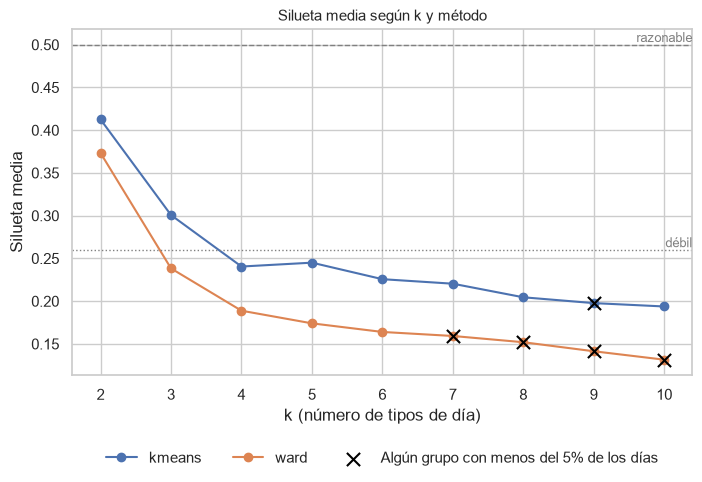

In [61]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for metodo, g in tabla_k.groupby('metodo'):
    ax.plot(g['k'], g['silueta'], marker='o', label=metodo)
    sin = g[~g['cumple_tamano']]
    ax.scatter(sin['k'], sin['silueta'], marker='x', s=90, color='black', zorder=5)

ax.scatter([], [], marker='x', s=90, color='black',
           label=f'Algún grupo con menos del {TAMANO_MIN_GRUPO:.0%} de los días')
for y, texto, estilo in [(SILUETA_RAZONABLE, 'razonable', '--'), (SILUETA_DEBIL, 'débil', ':')]:
    ax.axhline(y, color='gray', ls=estilo, lw=1)
    ax.text(ax.get_xlim()[1], y, texto, ha='right', va='bottom', fontsize=9, color='gray')

ax.set_xticks(sorted(tabla_k['k'].unique()))
ax.set_xlabel('k (número de tipos de día)')
ax.set_ylabel('Silueta media')
ax.set_title('Silueta media según k y método')
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.18), ncol=3)
plt.show()

In [62]:
mejor = recomendar_k(tabla_k)
print(f"Mayor silueta con grupos de al menos {TAMANO_MIN_GRUPO:.0%}: {mejor['metodo']}, "
      f"k = {int(mejor['k'])}, silueta = {mejor['silueta']:.3f} ({mejor['interpretacion']})")

K = int(K_ELEGIDO) if K_ELEGIDO else int(mejor['k'])
METODO = METODO_ELEGIDO or mejor['metodo']
fila = tabla_k[(tabla_k['k'] == K) & (tabla_k['metodo'] == METODO)].iloc[0]
SILUETA = float(fila['silueta'])
print(f"Se usa: {METODO}, k = {K}, silueta = {SILUETA:.3f}, grupo más pequeño = {fila['min_tamano']:.1%}")
if K > 8:
    print("Aviso: con más de 8 grupos los colores categóricos dejan de distinguirse bien.")

# Alternativas con más detalle (k >= 4)
tabla_k[tabla_k['cumple_tamano'] & (tabla_k['k'] >= 4)].nlargest(3, 'silueta').round(3)

Mayor silueta con grupos de al menos 5%: kmeans, k = 2, silueta = 0.413 (estructura débil)
Se usa: kmeans, k = 2, silueta = 0.413, grupo más pequeño = 38.2%


,metodo,k,silueta,min_tamano,cumple_tamano
3,kmeans,5,0.245,0.166,True
2,kmeans,4,0.240,0.176,True
4,kmeans,6,0.226,0.064,True


**Decisión de k.** Con frecuencia k = 2 gana en silueta, porque dividir en dos es lo más fácil. Si ocurre, no basta con quedarse con ese número: la tabla de arriba permite justificar un k mayor si sus grupos son más útiles e interpretables, aunque la silueta baje algo. Para fijarlo, usar `K_ELEGIDO` en la sección 0.

**Justificación: k-medias con k = 2.** Es la única combinación con estructura *débil* pero apreciable (silueta 0.413); k = 3 baja a 0.301 (grupo más pequeño: 26.8 %) y desde k = 4 cae por debajo de 0.26 (0.240 con k = 4 y 0.245 con k = 5, ambos con grupos de 16.7–17.6 %), el umbral de «sin estructura sustancial». Ward queda por debajo de k-medias en todos los k (0.373 con k = 2) y los dos métodos coinciden bastante (Rand ajustado 0.82), así que el resultado no depende del método. Todos los grupos cumplen el mínimo del 5 %.

La decisión tiene un costo: k = 2 solo recoge la estación, no hay un tipo de día de fin de semana (sección 9.2). Como los perfiles forman más un continuo que grupos separados, subir k no habría dado categorías más nítidas, solo más fragmentación. Si se quiere explorar un detalle mayor, `K_ELEGIDO = 3` es el único candidato con silueta cercana al umbral.

## 9. Agrupamiento y descripción de los grupos

`agrupar` asigna **todos** los días a un grupo (el 1 es el más frecuente). Si el método es Ward, se ajusta sobre una muestra y el resto de días se asigna al centro más cercano. Para saber si el resultado depende del método, se calcula el **índice de Rand ajustado** entre k-medias y Ward con el mismo k (1 = grupos idénticos; cerca de 0 = sin relación).

In [63]:
etiquetas = agrupar(perfiles, K, METODO)

otro = 'ward' if METODO == 'kmeans' else 'kmeans'
ari = adjusted_rand_score(etiquetas, agrupar(perfiles, K, otro))
print(f"Concordancia con {otro} (índice de Rand ajustado): {ari:.2f}")

Concordancia con ward (índice de Rand ajustado): 0.82


In [64]:
calendario = calendario_dias(df_agr)
resumen = describir_grupos(perfiles, etiquetas, calendario).rename_axis('grupo')

print(f"Los porcentajes suman {resumen['pct_dias'].sum():.1f} %")
print("Todos los grupos tienen al menos el 5 % de los días:", bool(resumen['cumple_tamano'].all()))
resumen.round(1)

Los porcentajes suman 100.0 %
Todos los grupos tienen al menos el 5 % de los días: True


,n_dias,pct_dias,hora_pico,hora_minimo,amplitud,pct_fin_de_semana,pct_festivo,estacion_dominante,pct_estacion_dominante,cumple_tamano
grupo,,,,,,,,,,
1,28299,62.3,19,3,0.2,28.9,3.2,Invierno,38.1,True
2,17131,37.7,17,4,0.4,28.1,2.8,Verano,63.0,True


**Cómo leer la tabla.** `hora_pico` y `hora_minimo` son horas de inicio (0 = 00:00–01:00). `amplitud` es la diferencia entre el máximo y el mínimo de la curva, en fracción del promedio del día. `pct_fin_de_semana` es el porcentaje de días del grupo que son sábado o domingo (si los fines de semana fueran independientes del grupo, sería cercano a 28.6 %). `estacion_dominante` y `pct_estacion_dominante` indican en qué estación cae la mayoría de los días del grupo.

In [65]:
def nombre_sugerido(g, fila):
    """Nombre provisional a partir del calendario del grupo (revisar a mano)."""
    if fila['pct_fin_de_semana'] >= 60:
        dia = 'fin de semana'
    elif fila['pct_fin_de_semana'] <= 10:
        dia = 'laborable'
    else:
        dia = 'mixto'
    return f"G{g} · {fila['estacion_dominante']} · {dia}"

NOMBRES_AUTO = {g: nombre_sugerido(g, fila) for g, fila in resumen.iterrows()}   # solo como referencia

# Nombres definitivos, tras revisar las curvas y el calendario (secciones 9.1 a 9.3).
# Los automáticos dicen «mixto» en ambos grupos y llaman «Invierno» a un grupo que cubre de octubre a mayo.
NOMBRES = {1: 'Temporada fría (oct–may)', 2: 'Verano (jun–sep)'}
assert set(NOMBRES) == set(resumen.index), "Si cambia k, definir un nombre por grupo"
pd.Series(NOMBRES, name='nombre').to_frame()

,nombre
1,Temporada fría (oct–may)
2,Verano (jun–sep)


### 9.1 Forma de cada tipo de día

Curva media de cada grupo con una banda entre los percentiles 10 y 90. Todos los paneles comparten la misma escala, así que las formas se comparan por posición sobre un eje común. La línea gris marca el promedio del día (1.0).

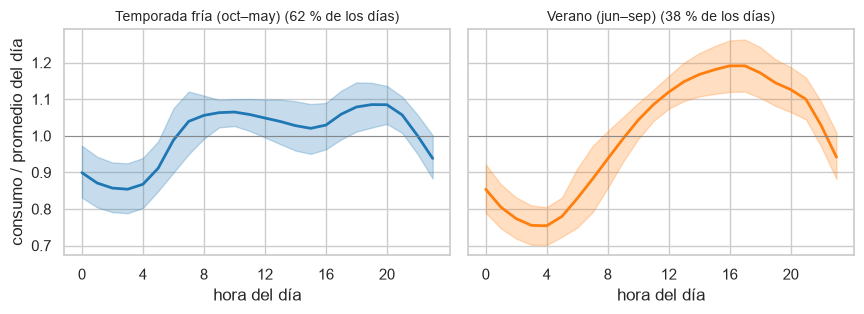

In [66]:
curvas = curvas_grupo(perfiles, etiquetas)
colores = list(sns.color_palette('tab10', max(K, 2)))[:K]
grupos = sorted(curvas['grupo'].unique())

ncols = min(4, K)
nrows = math.ceil(K / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4.4 * ncols, 3.3 * nrows),
                         sharex=True, sharey=True, squeeze=False)

for ax, g in zip(axes.flat, grupos):
    c = curvas[curvas['grupo'] == g]
    ax.fill_between(c['hora'], c['inferior'], c['superior'], color=colores[g - 1], alpha=0.25)
    ax.plot(c['hora'], c['media'], color=colores[g - 1], lw=2)
    ax.axhline(1, color='gray', lw=0.6)
    ax.set_title(f"{NOMBRES[g]} ({resumen.loc[g, 'pct_dias']:.0f} % de los días)", fontsize=10)
    ax.set_xticks(range(0, 24, 4))
for ax in axes.flat[len(grupos):]:
    ax.axis('off')
for ax in axes[-1]:
    ax.set_xlabel('hora del día')
for ax in axes[:, 0]:
    ax.set_ylabel('consumo / promedio del día')

fig.tight_layout()
plt.show()

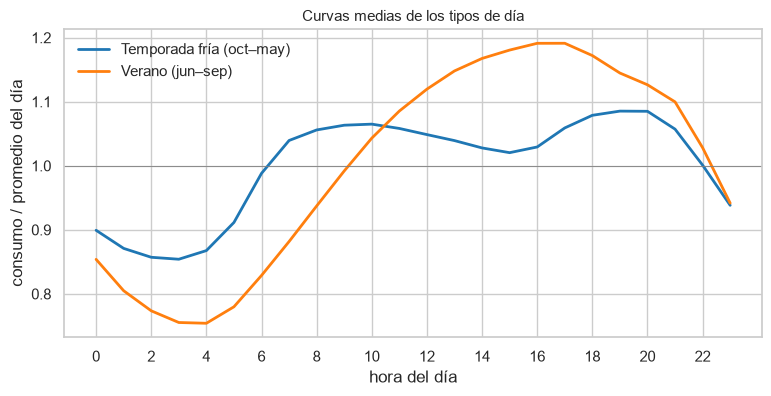

In [67]:
fig, ax = plt.subplots(figsize=(9, 4))
for g in grupos:
    c = curvas[curvas['grupo'] == g]
    ax.plot(c['hora'], c['media'], color=colores[g - 1], lw=2, label=NOMBRES[g])
ax.axhline(1, color='gray', lw=0.6)
ax.set_xticks(range(0, 24, 2))
ax.set_xlabel('hora del día')
ax.set_ylabel('consumo / promedio del día')
ax.set_title('Curvas medias de los tipos de día')
ax.legend()
plt.show()

**Interpretación.** Las dos curvas se distinguen sobre todo por la **amplitud** y por la hora del pico, no por tener picos en lugares distintos:

- **Grupo 1, temporada fría (62.3 % de los días).** Curva aplanada, con amplitud de ≈ 0.2 del promedio del día: mínimo hacia las 3 h (≈ 0.86), subida rápida entre las 5 y las 7 h hasta una meseta de ≈ 1.05–1.07 que dura toda la mañana y la tarde, y máximo nocturno a las 19 h (≈ 1.08). Es la forma de dos picos suavizados (mañana y noche) que se vio en invierno en la sección 1.2, y su banda entre percentiles es la más ancha, lo que indica que reúne días bastante heterogéneos.
- **Grupo 2, verano (37.7 %).** Una sola campana con mínimo a las 4 h (≈ 0.75) y máximo a las 16–17 h (≈ 1.19), con amplitud de ≈ 0.4: el doble de contraste entre madrugada y tarde, producto del aire acondicionado. La banda es más estrecha, es decir, los días calurosos se parecen mucho entre sí.
- **Diferencia clave:** el pico llega 2–3 horas más temprano en verano (17 h frente a 19 h) y es más alto y más agudo; en la temporada fría el consumo se reparte durante todo el día.
- **No aparece un pico claro hacia las 8 h** como grupo propio: queda absorbido en la meseta de mañana del grupo 1. Para verlo separado habría que subir k, a costa de una silueta ya débil.

### 9.2 Composición de cada grupo por día de la semana y por mes

Porcentaje de los días de cada grupo que cae en cada día de la semana y en cada mes. Si un grupo se concentra en sábados y domingos, o en una estación, el algoritmo capturó el calendario sin que se le diera.

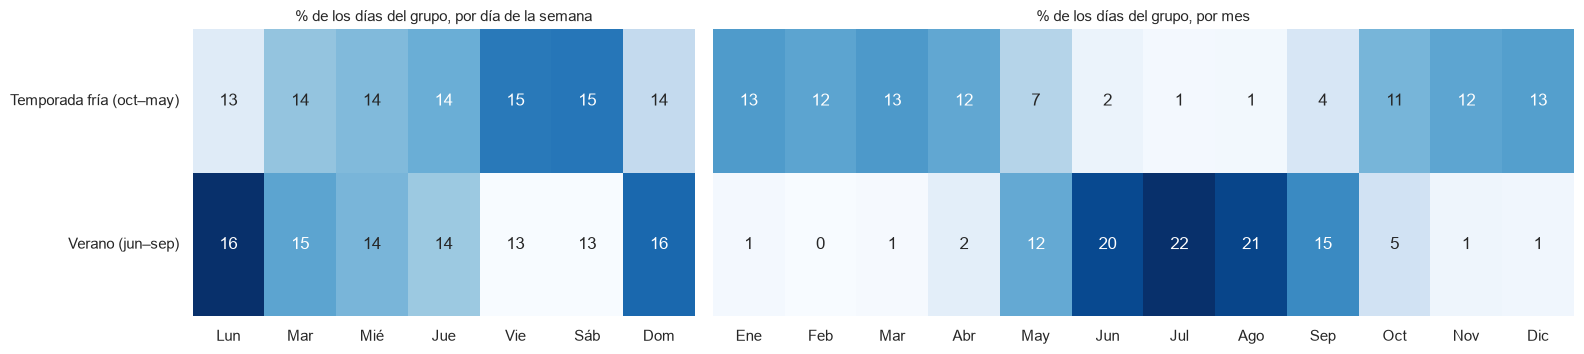

In [68]:
cal = calendario.reindex(perfiles.index)

por_dia = pd.crosstab(etiquetas, cal['dia_semana'], normalize='index').mul(100)
por_dia.columns = DIAS
por_mes = pd.crosstab(etiquetas, cal['mes'], normalize='index').mul(100)
por_mes.columns = MESES
for tabla in (por_dia, por_mes):
    tabla.index = [NOMBRES[g] for g in tabla.index]

fig, axes = plt.subplots(1, 2, figsize=(16, 0.6 * K + 2.5), gridspec_kw={'width_ratios': [7, 12]})
for ax, tabla, titulo in zip(axes, (por_dia, por_mes),
                             ['% de los días del grupo, por día de la semana',
                              '% de los días del grupo, por mes']):
    sns.heatmap(tabla, annot=True, fmt='.0f', cmap='Blues', cbar=False, ax=ax)
    ax.set_title(titulo)
    ax.set_ylabel('')
    ax.tick_params(axis='y', rotation=0)
axes[1].set_yticklabels([])
fig.tight_layout()
plt.show()

### 9.3 Calendario de una región

Cada fila es un año y cada columna un día del año; el color indica el tipo de día. Permite ver la ubicación de cada grupo en el calendario (estaciones, fines de semana, festivos) y si cambia con los años. Los espacios en blanco son días sin datos completos. La región se elige con `REGION_CALENDARIO`.

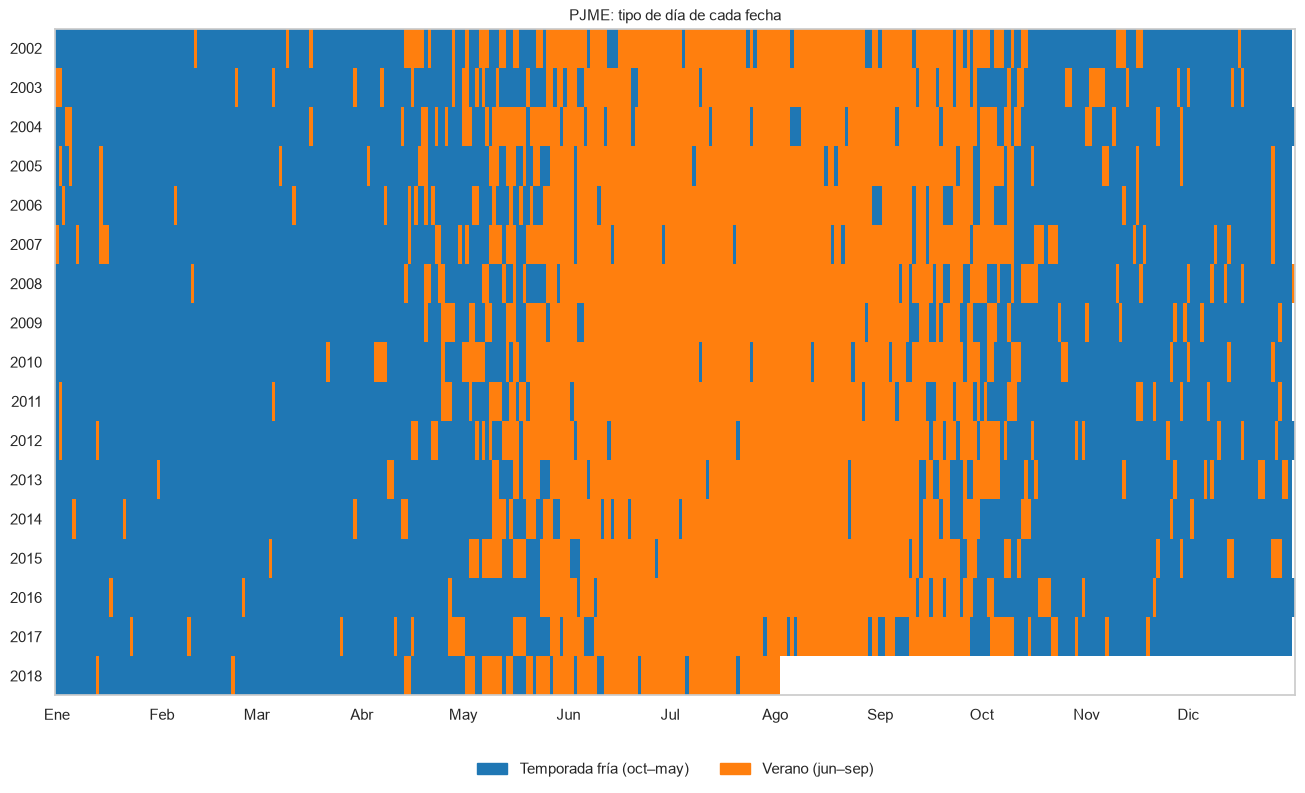

In [69]:
dias = etiquetas.xs(REGION_CALENDARIO, level='region').rename('grupo').reset_index()
dias['anio'] = dias['fecha'].dt.year
dias['doy'] = dias['fecha'].dt.dayofyear
m = dias.pivot(index='anio', columns='doy', values='grupo').reindex(columns=range(1, 367))

cmap = ListedColormap(colores)
cmap.set_bad('white')

fig, ax = plt.subplots(figsize=(16, 0.38 * len(m) + 2.2))
ax.imshow(np.ma.masked_invalid(m.to_numpy(dtype=float)), cmap=cmap, vmin=0.5, vmax=K + 0.5,
          aspect='auto', interpolation='nearest')

inicios_mes = [pd.Timestamp(2021, mes, 1).dayofyear - 1 for mes in range(1, 13)]   # columnas desde 0
ax.set_xticks(inicios_mes)
ax.set_xticklabels(MESES)
ax.set_yticks(range(len(m)))
ax.set_yticklabels(m.index)
ax.grid(False)
ax.set_title(f'{REGION_CALENDARIO}: tipo de día de cada fecha')
ax.legend(handles=[Patch(color=colores[g - 1], label=NOMBRES[g]) for g in grupos],
          loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=min(K, 4))
plt.show()

**Interpretación.** Los grupos siguen la **estación del año y no el calendario semanal**:

- **Por estación:** el grupo 1 se concentra de octubre a abril (11–13 % de sus días por mes) y el grupo 2 de junio a agosto (20–22 % por mes), con septiembre (15 %) y mayo (12 %) como meses de transición. En el calendario de `PJME` se ven dos bloques sólidos (azul de noviembre a abril, naranja de junio a agosto) y entre ellos franjas mezcladas en mayo y de septiembre a octubre, donde el tipo depende de si el día fue caluroso.
- **Excepciones dentro de cada bloque:** hay días sueltos del otro grupo, sobre todo días frescos en pleno verano (barras azules) y días templados en invierno (barras naranjas, mucho más escasas). Es el comportamiento esperable si el algoritmo detecta «día con aire acondicionado» frente a «día sin él».
- **Laborables y fines de semana:** no hay separación. El 28.9 % de los días del grupo 1 y el 28.1 % del grupo 2 son sábado o domingo, casi lo mismo que el 28.6 % esperado sin relación. La distribución por día de la semana es casi uniforme (13–16 % en ambos grupos); solo se aprecia una ligera inclinación del grupo 2 hacia lunes y domingo y del grupo 1 hacia viernes y sábado, que no cambia la lectura.
- **Festivos:** tampoco se concentran (3.2 % y 2.8 % de los días de cada grupo).
- **Años:** la estructura es estable; ningún grupo se limita a pocos años. A simple vista el bloque de verano de 2002–2008 se extiende algo más hacia septiembre y octubre que el de 2015–2017, lo que concuerda con la mezcla más veraniega de las regiones con historia antigua, pero es una impresión visual que no se cuantificó. Los espacios en blanco de agosto en adelante de 2018 son el final del dataset.

## 10. Diferencias entre regiones

### 10.1 Mezcla de tipos de día por región

Porcentaje de los días de cada región que pertenece a cada tipo. Las barras comparten una línea base común (0 a 100 %). Se ordenan por la proporción del grupo 1. Se muestra primero con todo el historial de cada región y luego solo con el **periodo común**: las regiones cubren periodos distintos (`PJM_Load` 1998–2002, `NI` 2004–2011, las otras hasta 2018) y el clima de cada periodo cambia la mezcla, así que la segunda es la comparación justa.

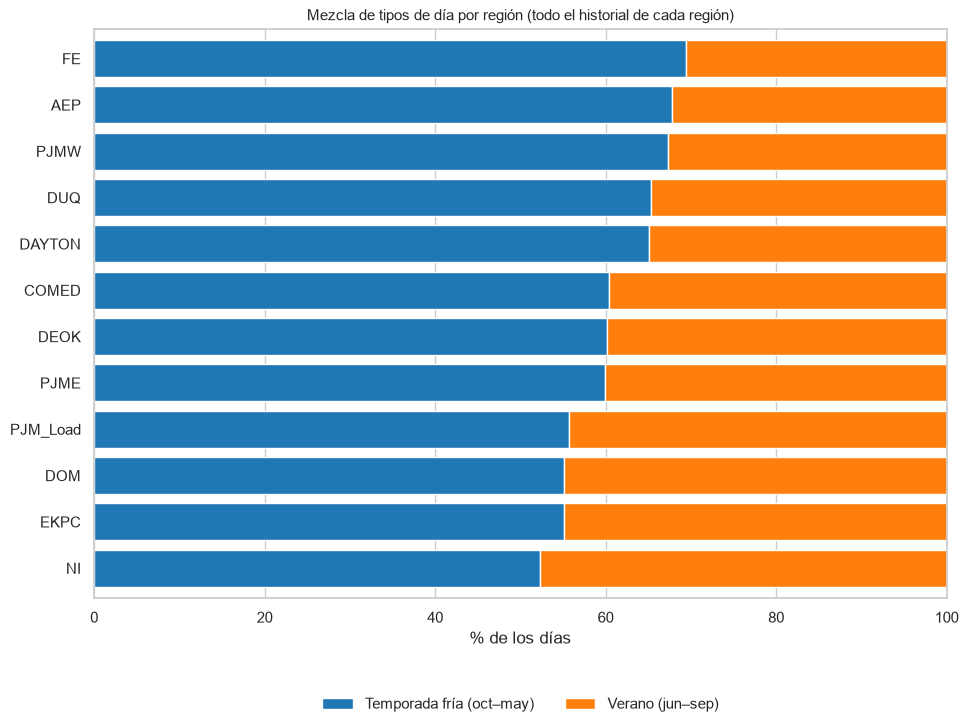

grupo,1,2
region,,
AEP,67.8,32.2
COMED,60.4,39.6
DAYTON,65.1,34.9
DEOK,60.2,39.8
DOM,55.2,44.8
DUQ,65.4,34.6
EKPC,55.2,44.8
FE,69.4,30.6
NI,52.3,47.7


In [70]:
def grafico_mezcla(tabla, titulo):
    """Barras apiladas horizontales: % de días de cada tipo por región."""
    orden = tabla.sort_values(grupos[0]).index
    t = tabla.loc[orden].rename(columns=NOMBRES)
    fig, ax = plt.subplots(figsize=(11, 0.45 * len(t) + 2))
    t.plot(kind='barh', stacked=True, color=colores, width=0.8, ax=ax)
    ax.set_xlim(0, 100)
    ax.set_xlabel('% de los días')
    ax.set_ylabel('')
    ax.set_title(titulo)
    ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.15), ncol=min(K, 3))
    plt.show()


mezcla = mezcla_por_region(etiquetas)
grafico_mezcla(mezcla, 'Mezcla de tipos de día por región (todo el historial de cada región)')
mezcla.round(1)

Regiones vigentes (10): ['AEP', 'COMED', 'DAYTON', 'DEOK', 'DOM', 'DUQ', 'EKPC', 'FE', 'PJME', 'PJMW']
Periodo común (días operativos): 2013-06-01 → 2018-08-02


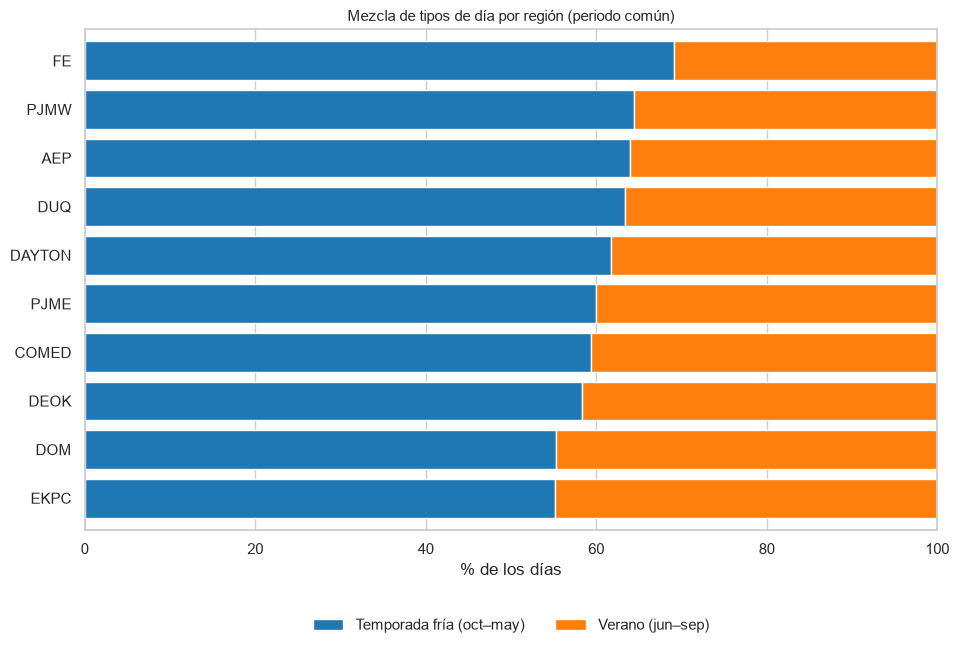

grupo,1,2
region,,
AEP,64.0,36.0
COMED,59.3,40.7
DAYTON,61.8,38.2
DEOK,58.3,41.7
DOM,55.3,44.7
DUQ,63.3,36.7
EKPC,55.2,44.8
FE,69.1,30.9
PJME,60.0,40.0


In [71]:
rango = df_agr.groupby('region')['fecha'].agg(['min', 'max'])
vig_ag = rango[rango['max'] >= rango['max'].max() - pd.Timedelta(days=7)]
ini_ag, fin_ag = vig_ag['min'].max(), vig_ag['max'].min()
print(f"Regiones vigentes ({len(vig_ag)}): {list(vig_ag.index)}")
print(f"Periodo común (días operativos): {ini_ag:%Y-%m-%d} → {fin_ag:%Y-%m-%d}")

fechas = etiquetas.index.get_level_values('fecha')
regs_et = etiquetas.index.get_level_values('region')
en_comun = regs_et.isin(vig_ag.index) & (fechas >= ini_ag) & (fechas <= fin_ag)

mezcla_comun = mezcla_por_region(etiquetas[en_comun])
grafico_mezcla(mezcla_comun, 'Mezcla de tipos de día por región (periodo común)')
mezcla_comun.round(1)

### 10.2 Estacionalidad frente a variabilidad dentro del día

Cada punto es una región del periodo común. El eje horizontal es el consumo medio de invierno entre el de verano (mayor que 1: región invernal) y el vertical es la amplitud media de su curva diaria (máximo menos mínimo, en fracción del promedio del día).

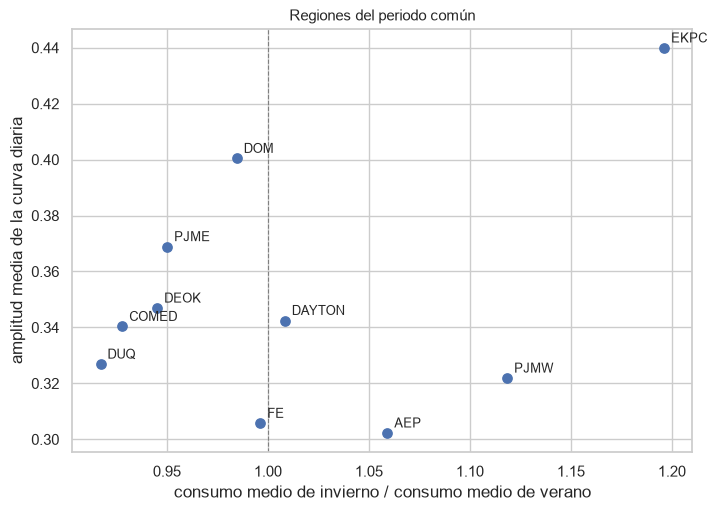

,invierno_verano,amplitud_diaria
region,,
AEP,1.059,0.302
COMED,0.928,0.340
DAYTON,1.008,0.342
DEOK,0.945,0.347
DOM,0.985,0.400
DUQ,0.917,0.327
EKPC,1.196,0.440
FE,0.996,0.306
PJME,0.950,0.369


In [72]:
df_c = df_agr[df_agr['region'].isin(vig_ag.index) & df_agr['fecha'].between(ini_ag, fin_ag)]
est = df_c.groupby(['region', 'estacion'])['MW'].mean().unstack()

perfiles_c = perfiles[en_comun]
disp = pd.DataFrame({
    'invierno_verano': est['Invierno'] / est['Verano'],
    'amplitud_diaria': (perfiles_c.max(axis=1) - perfiles_c.min(axis=1)).groupby('region').mean(),
})

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.scatter(disp['invierno_verano'], disp['amplitud_diaria'], s=45)
for nombre, r in disp.iterrows():
    ax.annotate(nombre, (r['invierno_verano'], r['amplitud_diaria']),
                xytext=(5, 4), textcoords='offset points', fontsize=9)
ax.axvline(1, color='gray', lw=0.8, ls='--')
ax.set_xlabel('consumo medio de invierno / consumo medio de verano')
ax.set_ylabel('amplitud media de la curva diaria')
ax.set_title('Regiones del periodo común')
plt.show()

disp.round(3)

**Interpretación.** En el periodo común la proporción de días de verano (grupo 2) va de 30.9 % (`FE`) a 44.8 % (`EKPC`):

- **Más días de verano:** `EKPC` (44.8 %) y `DOM` (44.7 %), seguidas de `DEOK` (41.7 %), `COMED` (40.7 %) y `PJME` (40.0 %).
- **Menos días de verano:** `FE` (30.9 %), `PJMW` (35.6 %), `AEP` (36.0 %) y `DUQ` (36.7 %).
- **Regiones que se parecen:** `DOM` y `EKPC` son casi idénticas (55.3 % y 55.2 % en el grupo 1); `COMED`, `DEOK` y `PJME` forman otro bloque (≈ 40 % en el grupo 2); `AEP`, `PJMW` y `DUQ` forman un tercero con ≈ 36 %.
- **Relación con el sesgo invernal o veraniego (sección 3):** la mezcla **no** sigue la razón invierno/verano. `EKPC` es la región más invernal (1.20) y aun así tiene más días de forma veraniega; `PJMW` (1.12) está entre las que menos. En cambio, sí acompaña a la **amplitud diaria** de la sección 10.2: `EKPC` (0.44) y `DOM` (0.40) tienen la mayor amplitud y más días del grupo 2, y `FE` (0.31) y `AEP` (0.30) la menor y menos días del grupo 2 (con alguna excepción, como `PJME`). El grupo 2 se define por una curva diaria con mucho contraste; las regiones con curvas más contrastadas, o más pequeñas y por tanto más sensibles a la temperatura, caen más a menudo en él, tengan o no su récord en verano.
- **Cautela:** con todo el historial las diferencias se mezclan con los años cubiertos (`NI` 52.3 % y `PJM_Load` 55.7 % en el grupo 1 cubren épocas distintas), por eso la comparación válida es la del periodo común.

## 11. Días que no encajan en su grupo

La distancia de un día al centro de su grupo (raíz de la suma de los cuadrados de las diferencias en las 24 horas, en unidades del perfil normalizado) mide cuánto se aleja su forma de la de su tipo. Un día muy lejano es un candidato a atípico por forma. Esta lista es un **insumo** para la detección de anomalías del notebook 03_pronostico_anomalias, que se basa en los residuos del pronóstico y no en la forma.

Como la distancia no es comparable entre regiones (las pequeñas, como `EKPC`, tienen curvas más ruidosas), se agrega `distancia_rel`: la distancia dividida entre la mediana de su región.

In [73]:
centroides = perfiles.groupby(etiquetas).mean()
diferencia = perfiles.to_numpy() - centroides.loc[etiquetas].to_numpy()
distancia = pd.Series(np.sqrt((diferencia ** 2).sum(axis=1)), index=perfiles.index, name='distancia_centroide')
distancia_rel = (distancia / distancia.groupby('region').transform('median')).rename('distancia_rel')

print("Distribución de la distancia por grupo")
display(distancia.groupby(etiquetas).describe(percentiles=[0.5, 0.95, 0.99]).round(3))

print("Los 10 días más alejados de su grupo (distancia absoluta)")
display(distancia.nlargest(10).to_frame().join(distancia_rel).join(etiquetas)
        .join(cal[['dia_semana', 'es_festivo', 'estacion']]).round(3))

print("Los 10 días más alejados respecto a la mediana de su región (comparable entre regiones)")
display(distancia_rel.nlargest(10).to_frame().join(distancia).join(etiquetas)
        .join(cal[['dia_semana', 'es_festivo', 'estacion']]).round(3))

Distribución de la distancia por grupo


,count,mean,std,min,50%,95%,99%,max
grupo,,,,,,,,
1,28299.0,0.226,0.103,0.044,0.210,0.397,0.609,1.539
2,17131.0,0.223,0.088,0.035,0.215,0.382,0.485,0.813


Los 10 días más alejados de su grupo (distancia absoluta)


distancia_centroide  distancia_rel  grupo  dia_semana  \
region fecha                                                               
DAYTON 2008-09-14                1.539          7.490      1           6   
EKPC   2017-02-10                1.148          3.474      1           4   
DAYTON 2012-06-29                1.113          5.414      1           4   
EKPC   2014-03-07                1.090          3.298      1           4   
       2018-01-07                1.080          3.268      1           6   
       2018-02-09                1.045          3.164      1           4   
       2014-11-19                1.038          3.140      1           2   
       2017-03-16                1.036          3.135      1           3   
DOM    2015-03-07                1.028          4.019      1           5   
EKPC   2014-02-28                1.016          3.077      1           4   

                   es_festivo   estacion  
region fecha                              
DAYTON 2008-09-14       False      Otoño  
EKPC   2017-02-10       False   Invierno  
DAYTON 2012-06-29       False     Verano  
EKPC   2014-03-07       False  Primavera  
       2018-01-07       False   Invierno  
       2018-02-09       False   Invierno  
       2014-11-19       False      Otoño  
       2017-03-16       False  Primavera  
DOM    2015-03-07       False  Primavera  
EKPC   2014-02-28       False   Invierno

Los 10 días más alejados respecto a la mediana de su región (comparable entre regiones)


distancia_rel  distancia_centroide  grupo  dia_semana  \
region fecha                                                               
DAYTON 2008-09-14          7.490                1.539      1           6   
       2012-06-29          5.414                1.113      1           4   
AEP    2012-06-29          4.986                0.908      1           4   
PJMW   2003-05-28          4.828                0.875      1           2   
DEOK   2012-06-29          4.076                0.813      2           4   
DOM    2015-03-07          4.019                1.028      1           5   
PJMW   2015-03-07          3.682                0.667      1           5   
AEP    2015-03-07          3.564                0.649      1           5   
DOM    2009-12-11          3.485                0.892      1           4   
EKPC   2017-02-10          3.474                1.148      1           4   

                   es_festivo   estacion  
region fecha                              
DAYTON 2008-09-14       False      Otoño  
       2012-06-29       False     Verano  
AEP    2012-06-29       False     Verano  
PJMW   2003-05-28       False  Primavera  
DEOK   2012-06-29       False     Verano  
DOM    2015-03-07       False  Primavera  
PJMW   2015-03-07       False  Primavera  
AEP    2015-03-07       False  Primavera  
DOM    2009-12-11       False   Invierno  
EKPC   2017-02-10       False   Invierno

**Lectura.** La distancia absoluta está dominada por regiones pequeñas (`EKPC` aparece 6 veces entre los 10 primeros) y por eso no sirve para comparar entre regiones. Con `distancia_rel` aparecen fechas que se repiten en **varias regiones a la vez**, que es una señal más fiable de un evento real que de un error de una sola serie:

- **2012-06-29** (`DAYTON`, `AEP`, `DEOK`): coincide con la ola de calor y la tormenta con cortes de energía de finales de junio de 2012, que ya figuraba entre los máximos de `DEOK` y `DUQ`.
- **2015-03-07** (`DOM`, `PJMW`, `AEP`): sábado de comienzos de marzo, sin festivo; la causa no está documentada en los datos y queda por verificar (¿frío tardío?).
- **2008-09-14** (`DAYTON`, el más lejano de todos, con distancia relativa 7.5): domingo que coincide con los cortes de energía por el paso de los restos del huracán Ike por Ohio. Podría ser un efecto real o datos estimados en la limpieza; conviene revisarlo.

Son hipótesis a partir de la fecha, no se confirmaron con fuentes externas. Todas caen en el grupo 1 salvo `DEOK` el 2012-06-29, que cae en el grupo 2 (verano). Son los candidatos naturales para contrastar con los residuos del pronóstico en el notebook 03_pronostico_anomalias.

## 12. Guardado

Tablas intermedias en `data/processed/` (el notebook 07 las convierte al formato final para Power BI):

| Archivo | Contenido |
|---|---|
| `tipos_de_dia.parquet` | Una fila por día y región: grupo, nombre, nivel (`MW_medio_dia`), distancia al centro (absoluta y relativa) y variables de calendario |
| `tipos_de_dia_curvas.parquet` | Curva media y banda por grupo y hora |
| `tipos_de_dia_resumen.parquet` | Descripción de cada grupo |
| `tipos_de_dia_mezcla_region.parquet` | Porcentaje de días de cada grupo por región (formato largo) |
| `tipos_de_dia_silueta_k.parquet` | Silueta y tamaño mínimo por método y k |

In [74]:
tipos = (tabla_dias(perfiles, etiquetas, nivel)
         .merge(pd.concat([distancia, distancia_rel], axis=1).reset_index(), on=['region', 'fecha'])
         .merge(calendario.reset_index(), on=['region', 'fecha']))
tipos['nombre_grupo'] = tipos['grupo'].map(NOMBRES)

curvas_g = curvas.assign(nombre_grupo=curvas['grupo'].map(NOMBRES))
resumen_g = resumen.reset_index().assign(nombre_grupo=lambda d: d['grupo'].map(NOMBRES))
mezcla_g = (mezcla.stack().rename('pct_dias').reset_index()
            .assign(nombre_grupo=lambda d: d['grupo'].map(NOMBRES)))

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
archivos = {
    'tipos_de_dia.parquet': tipos,
    'tipos_de_dia_curvas.parquet': curvas_g,
    'tipos_de_dia_resumen.parquet': resumen_g,
    'tipos_de_dia_mezcla_region.parquet': mezcla_g,
    'tipos_de_dia_silueta_k.parquet': tabla_k,
}
for nombre, tabla in archivos.items():
    tabla.to_parquet(PROCESSED_DIR / nombre, index=False)
    print(f"{nombre}: {len(tabla):,} filas")

tipos_de_dia.parquet: 45,430 filas
tipos_de_dia_curvas.parquet: 48 filas
tipos_de_dia_resumen.parquet: 2 filas
tipos_de_dia_mezcla_region.parquet: 24 filas
tipos_de_dia_silueta_k.parquet: 18 filas


## 13. Conclusiones y limitaciones

> **Nota:** las cifras salen de la última ejecución (`ALINEAR_HORA_CENTRAL = False`, k elegido automáticamente). Si se vuelve a ejecutar con otra configuración, hay que actualizar la interpretación.

### Hallazgos del análisis descriptivo (Parte A)

| Tema | Hallazgo |
|---|---|
| Hora, día de la semana y estación (HU-01) | El consumo toca fondo hacia las 3–4 h y alcanza su máximo entre las 17 y las 19 h (18 h en 7 de 10 regiones). Los fines de semana consumen ≈ 9 % menos que los laborables (de 4 % en EKPC a 14 % en DAYTON). En verano hay una sola curva con máximo por la tarde (hasta 1.2–1.4 del promedio); en invierno hay dos picos (≈ 7 h y 18–19 h); primavera y otoño son los más planos. |
| Estacionalidad y tendencia (HU-02) | Estacionalidad anual fuerte (en PJME el componente estacional oscila ≈ ±10 000 MW), con máximo en verano y repunte secundario en invierno. Sin crecimiento de largo plazo: PJME −9 % entre 2007 y 2017, AEP −13 %, DUQ −10 %, DOM ≈ +6 %. El tramo final de la tendencia STL es poco fiable (efecto de borde) y `period=365` es aproximado por los años bisiestos. |
| Comparación entre regiones (HU-03) | Tamaños muy distintos (PJME 31 478 MW de media frente a EKPC 1 464 MW): conviene comparar con `MW_rel`. COMED, DUQ, DEOK y PJME son de verano; EKPC (1.20) y PJMW (1.12) tienen sesgo invernal. Correlaciones diarias altas (0.56–0.96) por estacionalidad compartida; EKPC es la región más distinta. |
| Máxima demanda (HU-04) | Los récords son casi siempre olas de calor de verano (PJME 62 009 MW el 2-ago-2006). DOM, EKPC y PJMW tienen su récord el 20-feb-2015 a las 7 h. En las regiones de sesgo invernal hay un segundo grupo de picos diarios a las 7 h. El máximo de AEP (20-oct-2008) es atípico y conviene verificarlo. |
| Festivos | Un festivo consume ≈ 5 % menos que un laborable, aproximadamente la mitad del efecto de un fin de semana. Conserva la forma del día laborable, desplazada hacia abajo entre las 7 y las 20 h. Al ser festivos federales aproximados, el efecto real es mayor. |
| Empalmes | `NI` → `COMED` (cociente 1.00) es la misma zona (decisión D3, por confirmar); `PJM_Load` → `PJME` es compatible con una continuación; `PJMW` es una subzona aparte. |

### Hallazgos del agrupamiento (Parte B)

| Indicador | Valor |
|---|---|
| Días agrupados | 45 430 días de 12 regiones |
| Método y k | k-medias, k = 2 |
| Silueta media (muestra) | 0.413: estructura débil (≥ 0.50 razonable; 0.26 a 0.50 débil) |
| Grupo más pequeño | 37.7 % de los días |
| Concordancia k-medias vs. Ward (Rand ajustado) | 0.82 |

| Grupo | Nombre | % de los días | Hora pico | Calendario dominante |
|---|---|---|---|---|
| 1 | Temporada fría (oct–may) | 62.3 | 19 h | Octubre a mayo |
| 2 | Verano (jun–sep) | 37.7 | 17 h | Junio a septiembre |

- **Los dos tipos de día son estacionales, no de calendario.** No separan laborables de fines de semana (28.9 % y 28.1 % de sábados y domingos, casi igual que el 28.6 % esperado) ni concentran festivos.
- **Mezcla por región.** La proporción de días de verano va de ≈ 31 % (FE) a ≈ 45 % (DOM y EKPC) y sigue a la amplitud diaria de cada región más que a su sesgo invernal o veraniego.
- **Decisiones.** No se alineó la hora de `COMED` y `NI` (+1 h; ver 7.1) y se mantuvo k = 2 porque k ≥ 4 queda por debajo de silueta 0.26 y k = 3 apenas llega a 0.30 (ver 8).
- **Qué distingue a los grupos.** Amplitud (≈ 0.2 frente a ≈ 0.4 del promedio) y hora del pico (19 h frente a 17 h), no los picos de mañana ni el tipo de día de la semana.
- **Días atípicos por forma.** Las distancias absolutas se concentran en regiones pequeñas (EKPC, DAYTON); con `distancia_rel` destacan fechas compartidas por varias regiones (2012-06-29, 2015-03-07) y el 2008-09-14 en `DAYTON`, que pasan al notebook de anomalías para contrastarlos con los residuos.

### Limitaciones

- **Estructura débil.** Los perfiles diarios forman en parte un continuo: los tipos de día son una simplificación útil y no categorías naturalmente separadas. Con k ≥ 4 la silueta baja de 0.26 y con k = 3 es 0.30.
- **k = 2 solo captura la estación.** No hay un tipo de día de fin de semana; separarlo exige probar un k mayor y justificarlo aunque la silueta baje.
- **Sin temperatura.** Es el principal determinante de la demanda y el dataset no la incluye.
- **Se pierde el nivel.** Al dividir entre el promedio del día solo se compara la forma (el nivel queda en `MW_medio_dia`).
- **Agrupamiento conjunto.** Las 12 regiones comparten los tipos de día, lo que permite compararlas pero puede esconder formas propias de una región.
- **Periodos desiguales.** La mezcla de cada región depende de los años que cubre; por eso se compara también en el periodo común.
- **Hora de `COMED` y `NI`.** Sin alinear, su curva llega una hora más tarde y la comparación de formas se distorsiona.
- **Muestra para elegir k.** La silueta y Ward se calculan sobre una muestra de días; el ajuste final usa todos.
- **Festivos federales.** No incluyen los festivos propios de cada estado.